Lecture des données réalisée en 0.74408s


Text(0.5, 0, 'Erreur')

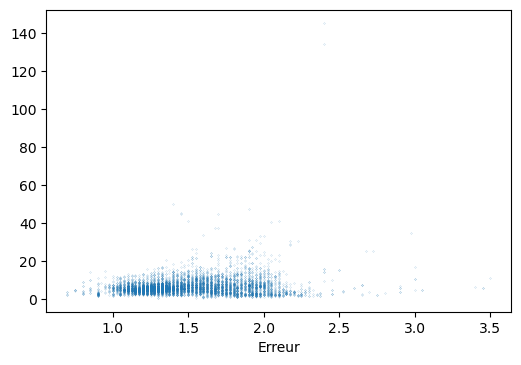

In [8]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

campagnes = ['campagne_carre']
data = get_bulk_data(read_data_from_campaigns(campagnes))


supports_data = np.zeros((len(data), 3))
supports_data[:] = np.nan
counter = 0

for test_id, test in data.items():
    with open(f'../KUBC_support_analysis/KUBC_support_analysis/{test_id}.txt') as f:
        for _ in range(2):
            next(f)
        supports_list = []
        for l in range(40):
            line = f.readline().split(' ')
            for it in line:
                try:
                    supports_list.append(float(it))
                except:
                    pass

    supports_data[counter, 0] = len(supports_list)/40  # Nb moyen de lien
    supports_data[counter, 1] = sum(supports_list)/len(supports_list) #incidence moyenne
    supports_data[counter, 2] = test.get_err((0,3))
    counter += 1

plt.scatter(supports_data[:,0],supports_data[:,2],s=0.01)
plt.xlabel('Nombre moyen de liens par support')
plt.xlabel('Erreur PBC-Panto')